# Analyse BRS Event Data

In [1]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from sixdegrees import sixdegrees

## Configurations

Load configuration file

This can be prepared using the *brs_make_config.ipynb* notebook

In [2]:
# event = "2024_06_28"
# event = "2024_04_03"
event = "2025_07_29"

# get config from yaml file
config = sixdegrees.load_from_yaml(f"./config/{event}.yaml")


Setup a sixdegrees instance

In [3]:
sd = sixdegrees(conf=config)

Get key information about the event

In [61]:
ev = sd.get_event_info(
    origin_time=config['origin_time'],
    base_catalog="USGS",
    magnitude=config['magnitude'],
    time_margin=100
)

Error getting event information from USGS:
No FDSN services could be discovered at 'http://earthquake.usgs.gov'. This could be due to a temporary service outage or an invalid FDSN service address.
No event found in USGS catalog for given time. Using dummy event info.


This will load the data from the data source:
- local mseed file
- local sds system
- fdsn (online)

and trim it to the time window

In [5]:
sd.load_data(config['tbeg'], config['tend'], resample_rate=config['resample_rate'])

-> fetching LI.LIV.IX.DHZ data from mseed file
-> fetching LI.LIV.IX.DHX data from mseed file
-> fetching LI.LIV.IX.DHY data from mseed file
-> translation inventory provided: metadata/station_LI_LIV.xml
-> removing response: VEL
3 Trace(s) in Stream:
LI.LIV.IX.DHZ | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:01.000000Z | 512.0 Hz, 3687425 samples
LI.LIV.IX.DHX | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:01.000000Z | 512.0 Hz, 3687425 samples
LI.LIV.IX.DHY | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:01.000000Z | 512.0 Hz, 3687425 samples
-> fetching LI.LIV.IY.DJX data from mseed file
-> fetching LI.LIV.IX.DJY data from mseed file
-> adding dummy trace: LI.LIV.IX.DJZ
-> rotation inventory provided: metadata/station_LI_LIV.xml
3 Trace(s) in Stream:
LI.LIV.IY.DJX | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:01.000000Z | 256.0 Hz, 1843713 samples
LI.LIV.IX.DJY | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:01.000000Z | 256.0 Hz, 1843713 samples
LI.LIV.IX.DJZ | 2025-07-2

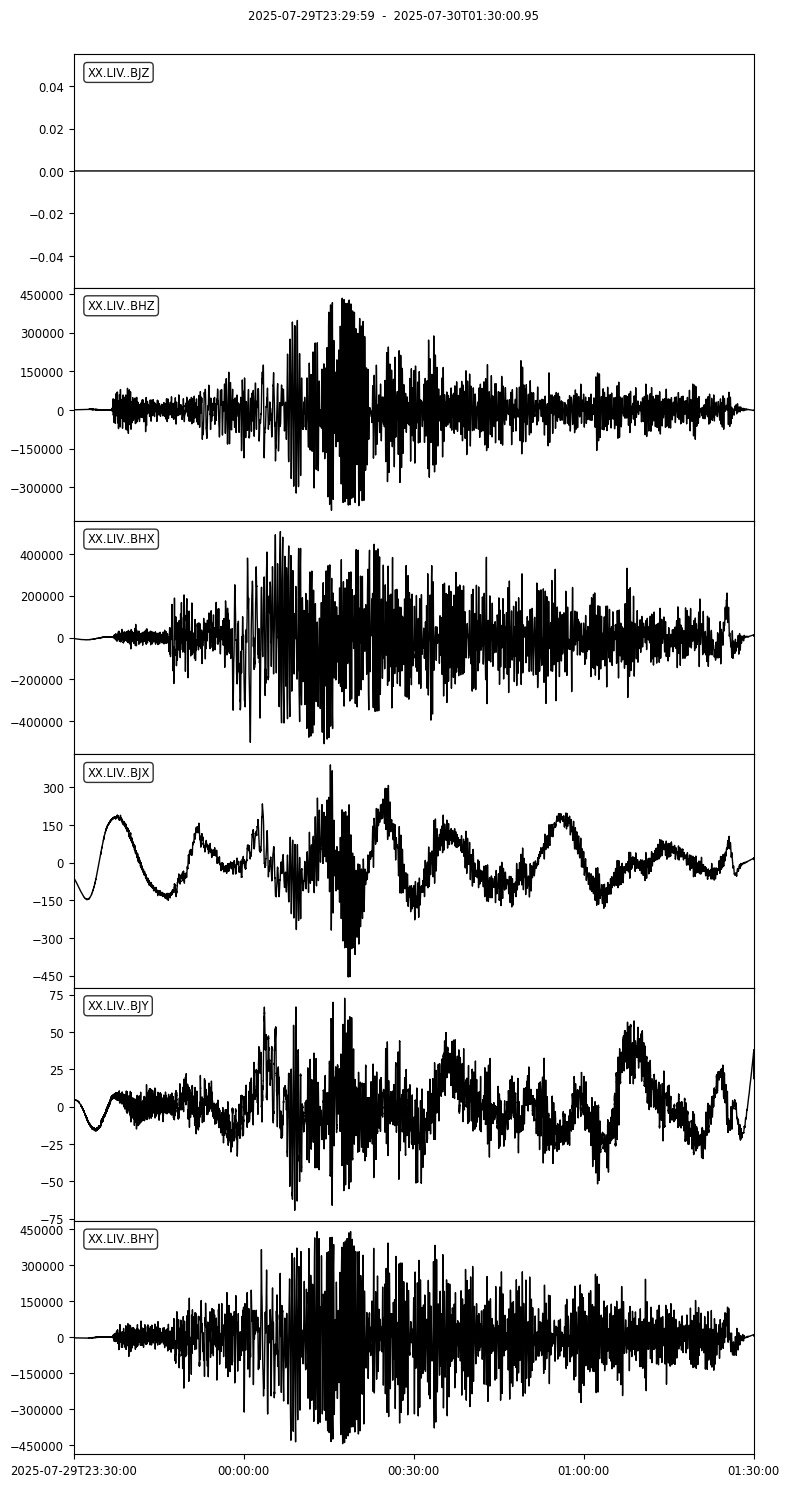

In [6]:
sd.st.plot(equal_scale=False);

Ensure that all traces of stream have the same sample size

In [7]:
sd.trim_stream(set_common=True, set_interpolate=False)

### Rotate data to ZNE

In [8]:
# as in file
IX = 162.2835
IY = 252.2835

code = "B"

from obspy.signal.rotate import rotate2zne

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*JZ")[0].data, 0, 90,
    sd.st.select(station="LIV", channel="*JX")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*JY")[0].data, IX, 0,
)
sd.st.select(station="LIV", channel="*JX")[0].data = E
sd.st.select(station="LIV", channel="*JX")[0].stats.channel = code+"JE"

sd.st.select(station="LIV", channel="*JY")[0].data = N
sd.st.select(station="LIV", channel="*JY")[0].stats.channel = code+"JN"

Z, N, E = rotated_data = rotate2zne(
    sd.st.select(station="LIV", channel="*HZ")[0].data, 0, -90,
    sd.st.select(station="LIV", channel="*HY")[0].data, IY, 0,
    sd.st.select(station="LIV", channel="*HX")[0].data, IX, 0,
)
sd.st.select(station="LIV", channel="*HX")[0].data = E
sd.st.select(station="LIV", channel="*HX")[0].stats.channel = code+"HE"

sd.st.select(station="LIV", channel="*HY")[0].data = N
sd.st.select(station="LIV", channel="*HY")[0].stats.channel = code+"HN"


In [9]:
# correct amplitudes from paul which has it in nanorad and nanometer/s

for tr in sd.st:
    if "H" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9 
    elif "J" in tr.stats.channel[1]:
        tr.data = tr.data / 1e9


### Wavelet Comparsion

In [10]:
# # First compute CWT for all components
# cwt_results = {}
# for comp in ['Z', 'N', 'E']:

#     try:
#         # Rotation components
#         rot_data = sd.get_stream("rotation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Rotation"] = sd.compute_cwt(
#             rot_data.times(), rot_data.data, rot_data.stats.delta,
#             normalize=True
#         )

#         del rot_data
#     except:
#         print(f"No {comp} data for rotation")
#     try:
#         # Translation components
#         acc_data = sd.get_stream("translation").select(channel=f"*{comp}")[0]
#         cwt_results[f"{comp}_Translation"] = sd.compute_cwt(
#             acc_data.times(), acc_data.data, acc_data.stats.delta,
#             normalize=True
#         )

#         del acc_data
#     except:
#         print(f"No {comp} data for translation")


In [11]:
# # Then plot all components
# fig = sixdegrees.plot_cwt_all(
#     rot=sd.get_stream("rotation"),
#     acc=sd.get_stream("translation"),
#     cwt_output=cwt_results,
#     clog=True,
#     ylim=1
# )

## Analysis

In [62]:
# Parameters to use for the analysis

# frequency band
fmin, fmax = 0.01, 0.1

# window factor
t_win_factor = 8

# overlap
Toverlap = 0.75

# cross-correlation threshold
cc_threshold = 0.8


In [63]:
# center frequency
fcenter = np.round(np.sqrt(fmax*fmin), 2)

# compute time window
Twindow = t_win_factor * int(1/fcenter)

print("Time window", Twindow, "seconds", "with center frequency", fcenter, "Hz")



Time window 264 seconds with center frequency 0.03 Hz


Frequency band to filter (this is applied to the stream object after being reset to raw stream)

In [64]:
sd.filter_data(fmin=fmin, fmax=fmax, output=False)

Apply polarity correction if needed. This is applied to the stream object that is processed. If raw is True, the polarity correction is applied to the raw stream too.

In [65]:
sd.polarity_stream(pol_dict={"HZ": 1, "JZ": 1}, raw=True)

-> polarity already applied. Exiting...


In [66]:
# sd.st.trim(starttime=sd.tbeg+200, endtime=sd.tend-4000)

Correct horizontal acceleration data

In [67]:
sd.correct_tilt()

In [68]:
# get cross-correlation function of JT and HZ and find the lag
from obspy.signal.cross_correlation import correlate, xcorr_max
from obspy.signal.rotate import rotate_ne_rt

JN = sd.get_stream("rotation").select(channel="*N")[0].data
JE = sd.get_stream("rotation").select(channel="*E")[0].data

JR, JT = rotate_ne_rt(JN, JE, ev['backazimuth'])

HZ = sd.get_stream("translation").select(channel="*Z")[0].data

cc0_before = correlate(JT, HZ, 0)

cc = correlate(JT, HZ, len(JT))

lag, cc_max = xcorr_max(cc)

HZ = np.roll(HZ, lag)

cc0_after = correlate(JT, HZ, 0)

print(lag, cc_max, cc0_before, cc0_after)

# sd.st.select(channel="*Z")[0].data = HZ



12 0.8843263248984057 [0.86719653] [0.88432632]


let's compare the waveforms of the rotation (red) and translational (black) components 

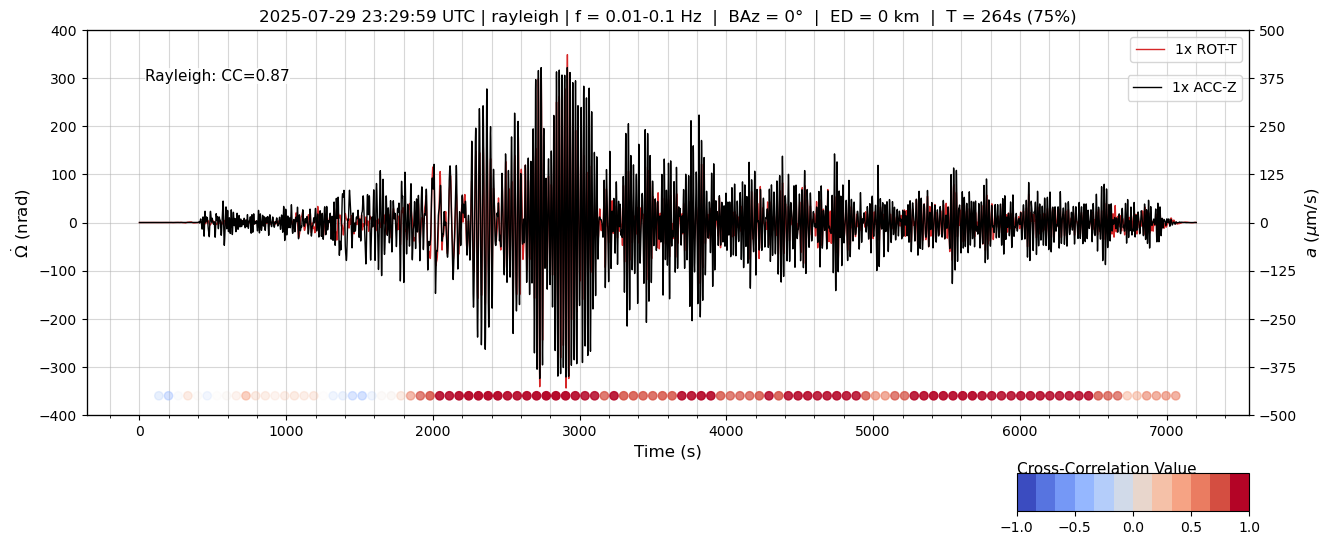

In [69]:
fig = sd.plot_waveform_cc(
    rot0=sd.get_stream("rotation"),
    acc0=sd.get_stream("translation"),
    baz=ev['backazimuth'],
    distance=ev['distance_km'],
    fmin=fmin,
    fmax=fmax,
    twin_sec=Twindow,
    twin_overlap=Toverlap,
    wave_type="rayleigh",
    runit=config['runit'],
    tunit=config['tunit']
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_waveform_cc.png", bbox_inches='tight')


In [70]:
# fig = sd.plot_spectra_comparison_fill(rot=sd.get_stream("rotation"), 
#                                       acc=sd.get_stream("translation"),
#                                       fmin=0.09, fmax=0.6,
#                                       ylog=False, xlog=False, fill=True
#                                       )

### Backazimuth Estimate

In [71]:
# compute backazimuth
baz_results = sd.compute_backazimuth(
    wave_type='rayleigh',
    baz_step=1,
    baz_win_sec=Twindow,
    baz_win_overlap=Toverlap,
    out=True
)


KeyboardInterrupt: 

baz_max = 339, baz_std = 38


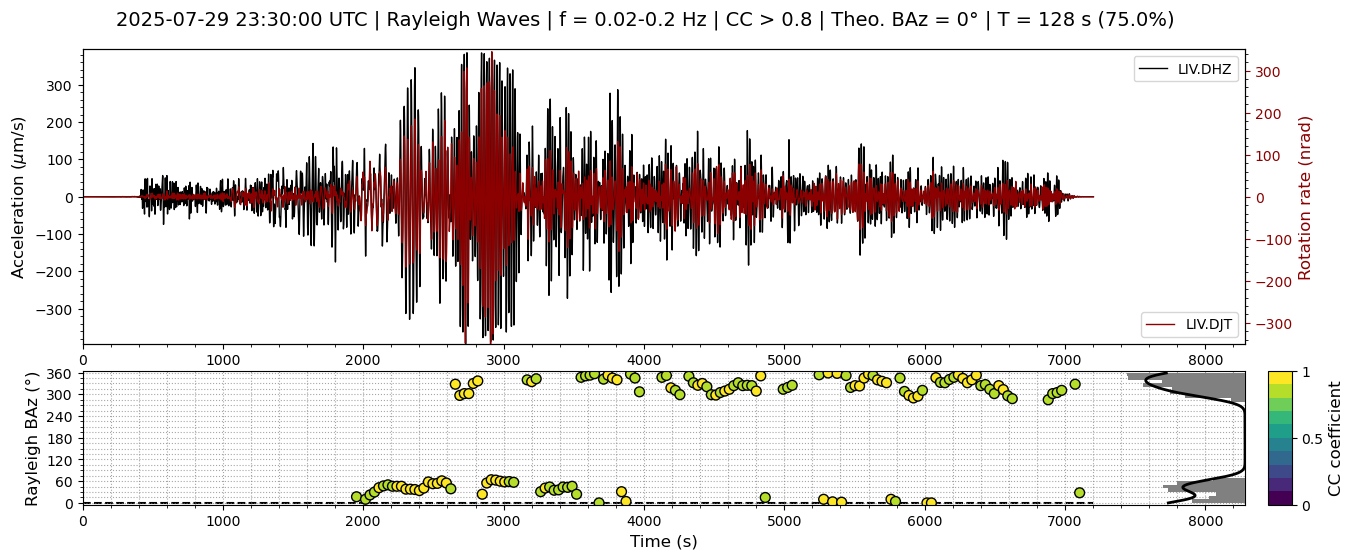

In [20]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='max',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_max.png", bbox_inches='tight')

baz_max = 350, baz_std = 9


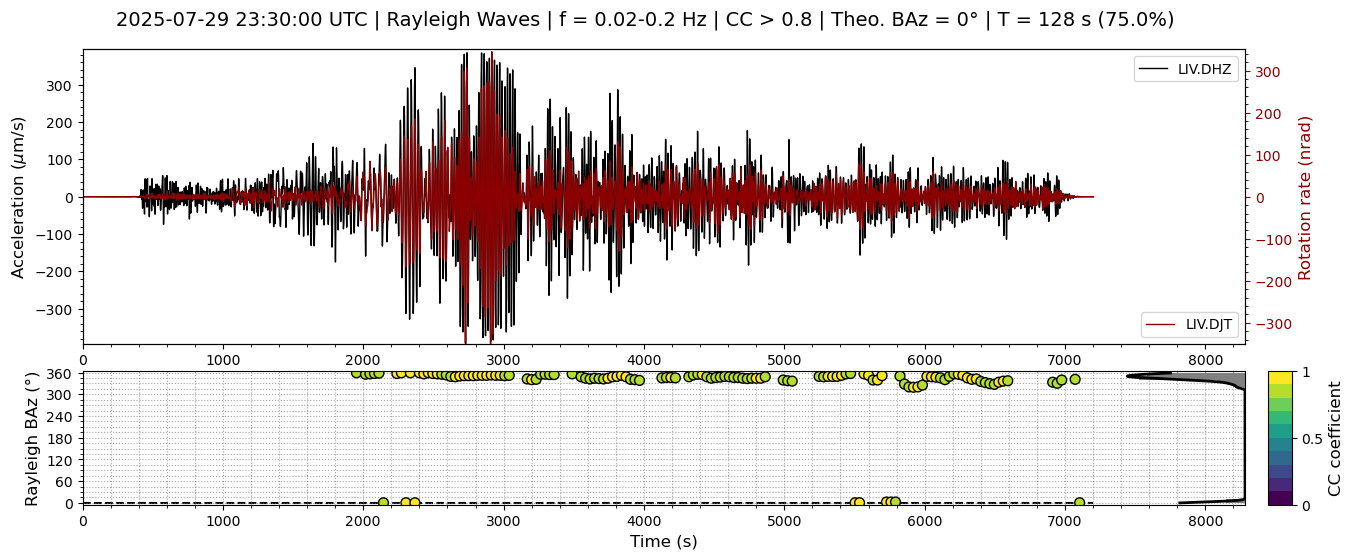

In [21]:
fig = sd.plot_backazimuth_results(
    baz_results,
    wave_type='rayleigh',
    baz_theo=ev['backazimuth'],
    cc_threshold=cc_threshold,  # optional
    cc_value='mid',
    unitscale='nano' # for rotation rate
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_mid.png", bbox_inches='tight')

### Estimate Phase Velocities

In [22]:
# estimate phase velocities
results_vel1 = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=Twindow,
    overlap=Toverlap,
    baz=ev['backazimuth'],
    method="ransac"

)

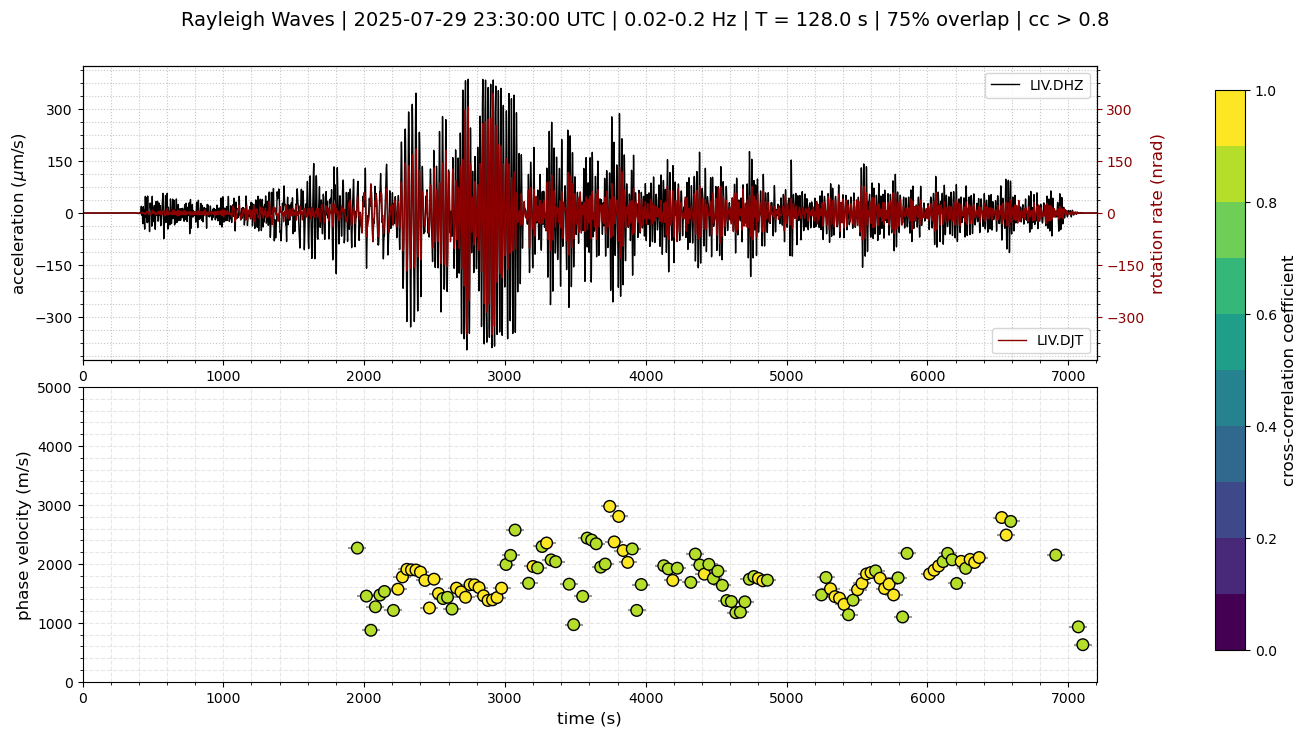

In [33]:
fig = sd.plot_velocities(
    results_vel1,
    cc_threshold=cc_threshold,
    vmax=5000
);

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities.png", bbox_inches='tight')

Compute phase velocity estimates based on an optimized approach wich the estimated backazimuth for rotation for each time window instead of the expected backazimuth

In [34]:
results_vel_adaptive = sd.compute_velocities_optimized(
    rotation_data=sd.get_stream("rotation", raw=False),
    translation_data=sd.get_stream("translation", raw=False),
    wave_type='rayleigh',
    baz_results=baz_results,
    baz_mode="mid",
    method="ransac",
    cc_threshold=0.5
)

results_vel_adaptive['parameters']['baz'] = ev['backazimuth']
results_vel_adaptive['ccoef'] = results_vel_adaptive['cc_value']
results_vel_adaptive['time'] = results_vel_adaptive['times']
results_vel_adaptive['terr'] = np.zeros_like(results_vel_adaptive['times'])

222it [00:01, 218.85it/s]


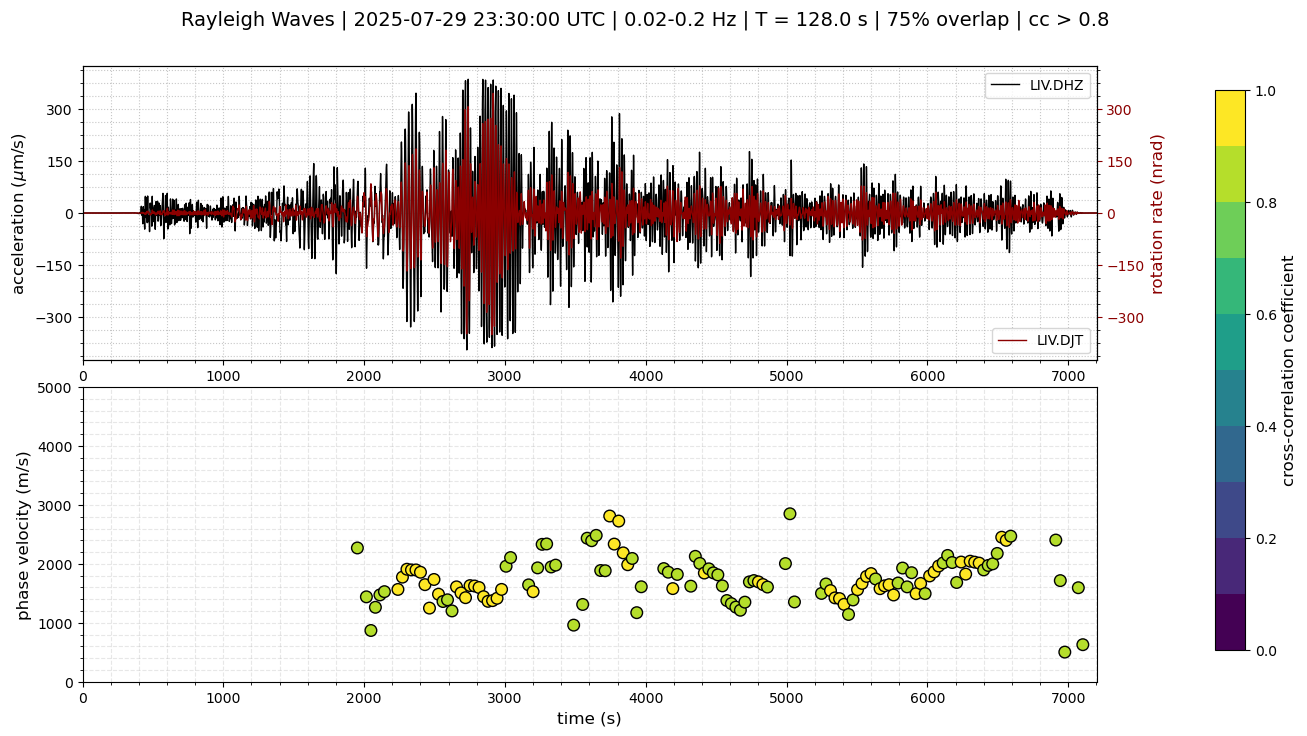

In [ ]:
fig = sd.plot_velocities(
    results_vel_adaptive, 
    cc_threshold=cc_threshold,
    vmax=5000
);

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities_adaptive.png", bbox_inches='tight')

In [36]:
from utils import plot_velocity_comparison

ImportError: cannot import name 'plot_velocity_comparison' from 'utils' (/home/andbro/cursorfiles/BRS/utils.py)

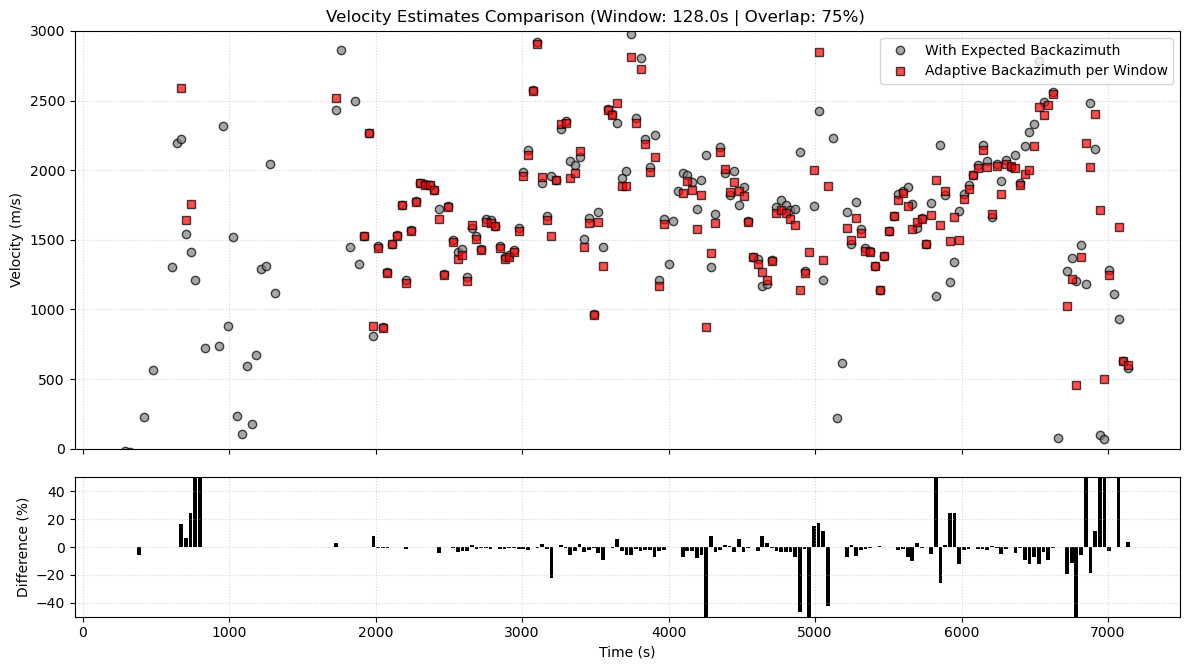

In [ ]:
fig = plot_velocity_comparison(
    results_vel1, results_vel_adaptive,
    labels=('With Expected Backazimuth', 'Adaptive Backazimuth per Window'),
    title='Velocity Estimates Comparison'
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_velocities_comparison.png", bbox_inches='tight')

### Plot Backazimuth Estimates on a Map

In [37]:
from utils import plot_backazimuth_map

In [45]:
results_map = sd.compute_backazimuth_map(
    wave_types=['rayleigh','tangent'],
    cc_threshold=cc_threshold,
)

Using precomputed rayleigh backazimuth results
Using precomputed tangent backazimuth results


#### Plot the Backazimuth Estimates on a Map

ERROR plotting theoretical great circle: Format specifier missing precision


/home/andbro/cursorfiles/BRS/utils.py:2351: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


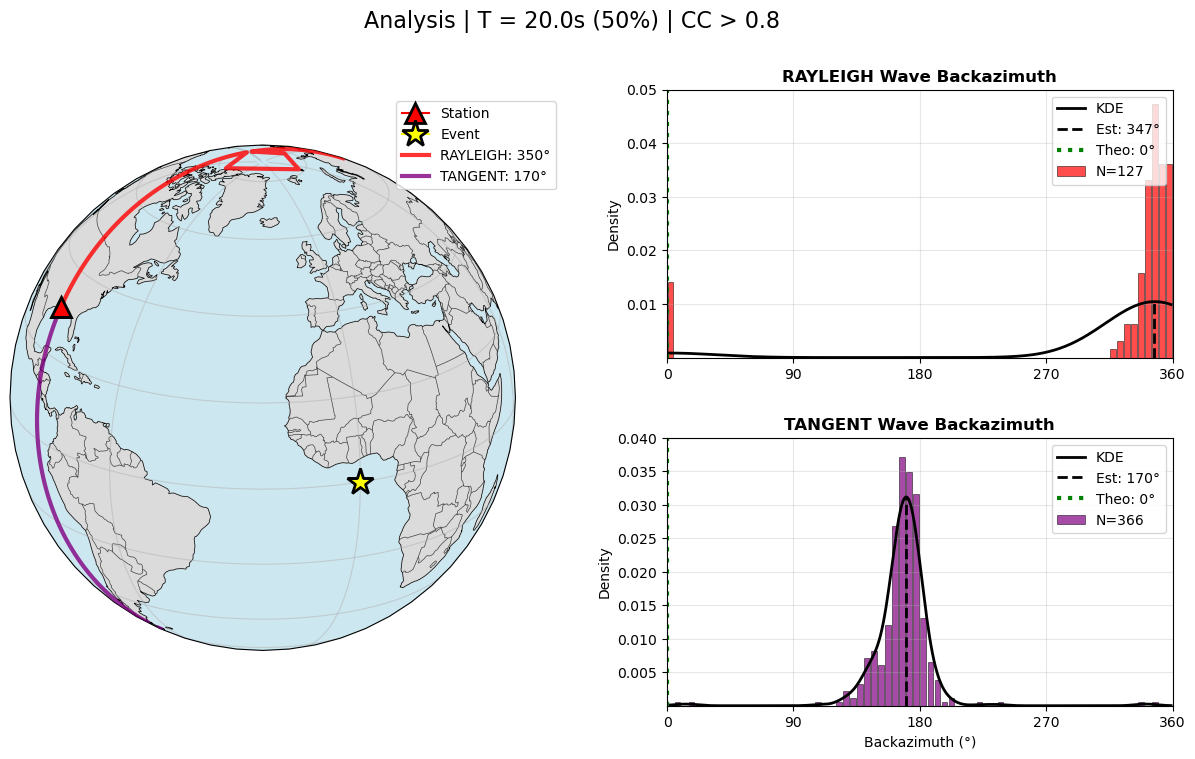

In [39]:
fig = plot_backazimuth_map(
    results_map,
    event_info=ev,
    map_projection='orthographic',  # 'orthographic' or 'platecarree'
    debug=False,
)

fig.savefig(f"{config['path_to_figures']}{config['project']}_backazimuth_map.png", bbox_inches='tight')

### Compute Velocity and Backazimuth with Frequency

Using ocatve bands to filter the data and then estimate the backazimuth and velocities

In [40]:
results_freq = sd.compute_frequency_dependent_parameters_parallel(
    wave_type='rayleigh',
    fbands={'fmin': 0.01, 'fmax': 0.5, 'octave_fraction': 3},
    t_win_factor=t_win_factor,
    overlap=Toverlap,
    baz_mode='mid',
    method='ransac',
    cc_threshold=cc_threshold,
    n_jobs=3
)

Processing 11 frequency bands using 3 processes...


Processing frequency bands:   0%|          | 0/11 [00:10<?, ?band/s]


KeyboardInterrupt: 

In [108]:
def plot_frequency_dependent(results_freq, data='vel', figsize=(12, 5), minors=True, fmin=None, fmax=None) -> plt.Figure:
    """
    Plot frequency-dependent velocity results with scatter points and connecting lines.
    
    Parameters
    ----------
    results_freq : Dict
        Results dictionary from compute_frequency_dependent_parameters
    data : str, optional
        Data to plot vel or baz, by default 'vel'
    figsize : Tuple[int, int], optional
        Figure size (width, height), by default (10, 6)
    minors : bool, optional
        Add minor ticks to axes if Tr   ue, by default True
    fmin : float, optional
        Minimum frequency to plot, by default None
    fmax : float, optional
        Maximum frequency to plot, by default None
        
    Returns
    -------
    matplotlib.figure.Figure
        The generated figure
    """
    import numpy as np
    import matplotlib.pyplot as plt
    
    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    
    # Get data
    frequencies = np.array(results_freq['frequency'])
    velocities = np.array(results_freq['velocity'])
    cc_values = np.array(results_freq['cc_values'])
    backazimuths = np.array(results_freq['backazimuth'])

    # Sort by frequency to ensure line plot connects points in order
    sort_idx = np.argsort(frequencies)
    frequencies = frequencies[sort_idx]
    velocities = velocities[sort_idx]
    cc_values = cc_values[sort_idx]
    backazimuths = backazimuths[sort_idx]

    # Create scatter plot with colorbar for CC values
    if data == 'vel':
        scatter = ax.scatter(frequencies, velocities, c=cc_values, 
                            cmap='viridis', s=100, alpha=1,
                            edgecolor='black', linewidth=1, zorder=5,
                            vmax=1)
        # Add connecting line
        ax.plot(frequencies, velocities, 'k-', alpha=0.3, zorder=2)

    elif data == 'baz':
        scatter = ax.scatter(frequencies, backazimuths, c=cc_values, 
                            cmap='viridis', s=100, alpha=1,
                            edgecolor='black', linewidth=1, zorder=5,
                            vmax=1)
        # Add connecting line
        ax.plot(frequencies, backazimuths, 'k-', alpha=0.3, zorder=2)

    # add error bars for mad
    if data == 'vel':
        try:
            mad = results_freq['vel_mad']
            ax.errorbar(frequencies, velocities, yerr=mad, fmt='none', ecolor='black', alpha=0.3, zorder=4)
        except:
            pass
    elif data == 'baz':
        try:
            mad = results_freq['baz_mad']
            ax.errorbar(frequencies, backazimuths, yerr=mad, fmt='none', ecolor='black', alpha=0.3, zorder=4)
        except:
            pass

    # Configure axes
    ax.set_xscale('log')
    ax.set_xlabel('Frequency (Hz)', fontsize=12)

    if data == 'vel':
        ax.set_ylabel('Apparent Phase Velocity (m/s)', fontsize=12)
    elif data == 'baz':
        ax.set_ylabel('Backazimuth (°)', fontsize=12)
    
    # Add grid
    ax.grid(True, which='major', alpha=0.3, zorder=1)
    if minors:
        ax.grid(True, which='minor', alpha=0.1, zorder=1)
        ax.minorticks_on()
    
    # Add colorbar
    cbar = plt.colorbar(scatter, pad=0.01)
    cbar.set_label('Cross-correlation coefficient', fontsize=12)

    # Set x-axis limits
    if fmin is not None:
        ax.set_xlim(left=fmin)
    if fmax is not None:
        ax.set_xlim(right=fmax)

    # Set y-axis limits based on data type
    if data == 'vel':
        ax.set_ylim(bottom=0)
    if data == 'baz':
        ax.set_ylim(bottom=0, top=360)

    # Add title
    if data == 'vel':
        title = f"{results_freq['parameters']['wave_type'].title()} Wave Velocity vs Frequency "
    elif data == 'baz':
        title = f"{results_freq['parameters']['wave_type'].title()} Wave Backazimuth vs Frequency "
    title += f"(win={results_freq['parameters']['t_win_factor']}/f, "
    title += f"overlap={results_freq['parameters']['overlap']*100:.0f}%, "
    title += f"method={results_freq['parameters']['method']})"
    ax.set_title(title, fontsize=14)
    
    plt.tight_layout()
    return fig

In [ ]:
from utils import plot_frequency_dependent

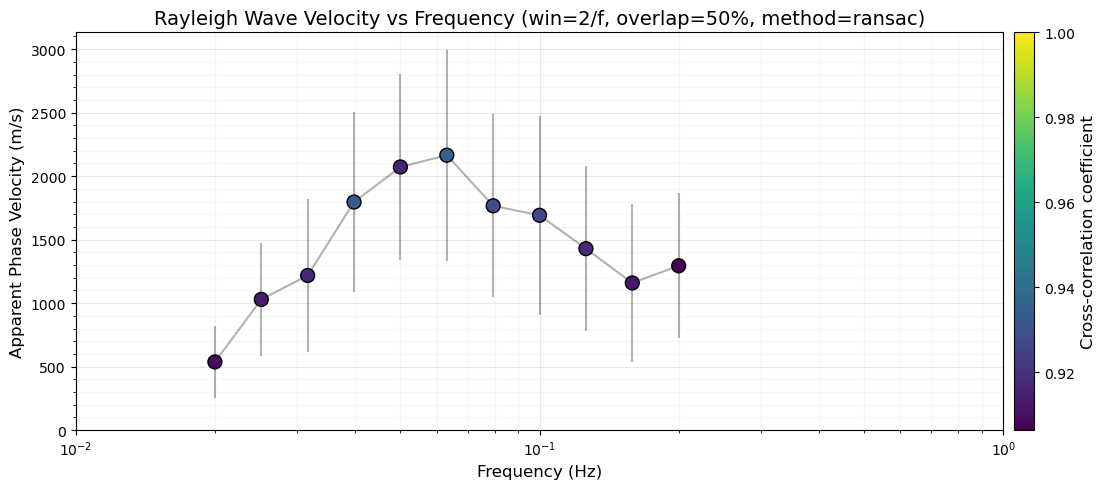

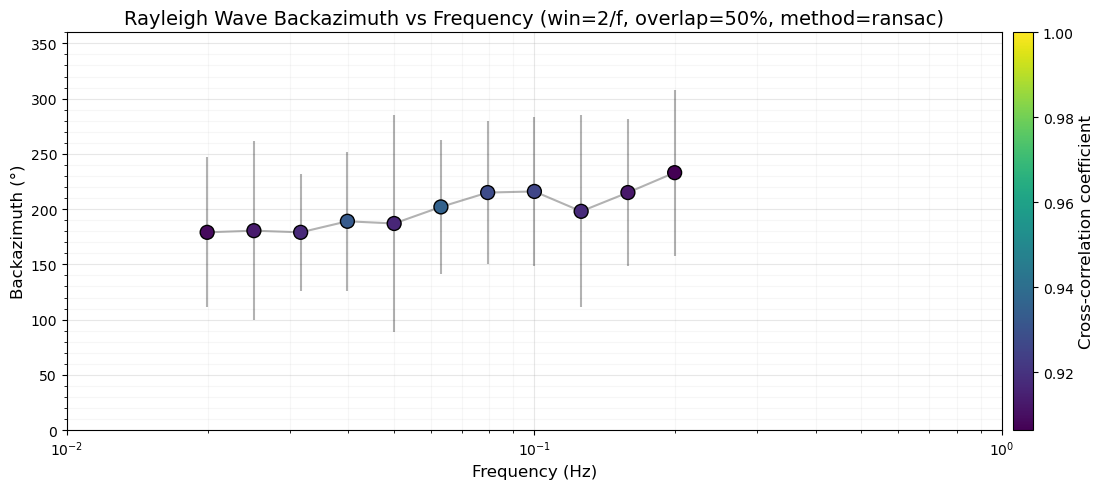

In [109]:
fig = plot_frequency_dependent(results_freq, data='vel', fmin=0.01, fmax=1);

fig = plot_frequency_dependent(results_freq, data='baz', fmin=0.01, fmax=1);

### Animate Waveforms

In [56]:
from utils import animate_waveforms

In [ ]:
# Basic usage (displays animation)
animate_waveforms(sd,
                  time_step=10,
                  show_arrivals=True,
                  rotate_zrt=True,
                  baz=ev['backazimuth'],
                  save_path=f"./figures/{config['project']}_animation.mp4")

Using backazimuth: 0°
3 Trace(s) in Stream:
XX.LIV..BJZ | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJR | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJT | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples 3 Trace(s) in Stream:
XX.LIV..BHZ | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BHR | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
XX.LIV..BJT | 2025-07-29T23:29:59.000000Z - 2025-07-30T01:30:00.950000Z | 20.0 Hz, 144040 samples
Animation parameters:
Duration: 7201.95s
Time step: 10.003s
Number of frames: 720
Frame rate: 0.1 fps
Theoretical P-arrival: 2025-07-29T23:24:50.000000Z
Theoretical S-arrival: 2025-07-29T23:24:50.000000Z


# Test Stuff

In [36]:
from obspy.signal.rotate import rotate_ne_rt

RR, RT = rotate_ne_rt(
    sd.get_stream("rotation").select(channel="*N")[0].data,
    sd.get_stream("rotation").select(channel="*E")[0].data,
    ev['backazimuth']
)

HR, HT = rotate_ne_rt(
    sd.get_stream("translation").select(channel="*N")[0].data,
    sd.get_stream("translation").select(channel="*E")[0].data,
    ev['backazimuth']
)

HZ = sd.get_stream("translation").select(channel="*Z")[0].data

TT = sd.get_stream("translation").select(channel="*Z")[0].times()



In [37]:
def plot_waveforms_and_envelope_products(stream_rot, stream_tra, baz_theo, 
                                         t_start=None, t_end=None, 
                                         smooth_window=0, figsize=(12, 10)):
    """
    Plot waveforms of RT, HZ, and HR components and their envelope products.
    
    Parameters:
    -----------
    stream_rot : obspy.Stream
        Stream containing rotation components
    stream_tra : obspy.Stream
        Stream containing translation components
    baz_theo : float
        Theoretical backazimuth in degrees
    t_start : obspy.UTCDateTime, optional
        Start time for plotting (defaults to stream start)
    t_end : obspy.UTCDateTime, optional
        End time for plotting (defaults to stream end)
    smooth_window : int
        Window size for optional smoothing of envelopes
    figsize : tuple
        Figure size
        
    Returns:
    --------
    matplotlib.figure.Figure
        Figure containing the plots
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.signal import hilbert
    from scipy.signal import savgol_filter
    from obspy.signal.rotate import rotate_ne_rt
    
    # Make copies of streams to avoid modifying originals
    rot_stream = stream_rot.copy()
    tra_stream = stream_tra.copy()
    
    # Get start and end times
    tbeg = max([tr.stats.starttime for tr in rot_stream + tra_stream])
    tend = min([tr.stats.endtime for tr in rot_stream + tra_stream])
    
    # Override with user-specified times if provided
    if t_start is not None:
        tbeg = t_start
    if t_end is not None:
        tend = t_end
    
    # Trim streams to desired time window
    rot_stream.trim(tbeg, tend)
    tra_stream.trim(tbeg, tend)
    
    # Get components
    try:
        # Rotation components
        RN = rot_stream.select(channel="*N")[0].copy()
        RE = rot_stream.select(channel="*E")[0].copy()
        
        # Translation components
        HZ = tra_stream.select(channel="*Z")[0].copy()
        HN = tra_stream.select(channel="*N")[0].copy()
        HE = tra_stream.select(channel="*E")[0].copy()
    except IndexError:
        raise ValueError("Required components not found in streams")
    
    # Get time array
    time = HZ.times()
    
    # Get data arrays
    rn = np.array(RN.data)
    re = np.array(RE.data)
    hz = np.array(HZ.data)
    hn = np.array(HN.data)
    he = np.array(HE.data)
    
    # Rotate to radial-transverse
    rr, rt = rotate_ne_rt(rn, re, baz_theo)
    hr, ht = rotate_ne_rt(hn, he, baz_theo)
    
    # Compute envelopes using Hilbert transform
    hz_env0 = np.abs(hilbert(hz))
    rt_env0 = np.abs(hilbert(rt))
    hr_env0 = np.abs(hilbert(hr))
    
    # Optional: smooth envelopes
    if smooth_window > 1:
        # Use Savitzky-Golay filter for smoothing
        hz_env0 = savgol_filter(hz_env0, smooth_window, 3)
        rt_env0 = savgol_filter(rt_env0, smooth_window, 3)
        hr_env0 = savgol_filter(hr_env0, smooth_window, 3)
    
    # Normalize envelopes
    hz_env = hz_env0 / np.max(hz_env0)
    rt_env = rt_env0 / np.max(rt_env0)
    hr_env = hr_env0 / np.max(hr_env0)
    
    # Compute envelope products
    hz_rt_env = hz_env * rt_env
    hr_rt_env = hr_env * rt_env
    hz_hr_env = hz_env * hr_env
    
    # Create figure
    fig, axes = plt.subplots(4, 1, figsize=figsize, sharex=True)
    
    # Plot RT component
    axes[0].plot(time, rt, 'r-', label='RT')
    axes[0].set_ylabel('JT\nAmplitude')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.3)
    axes[0].set_title(f'Component Waveforms and Envelopes (BAZ: {baz_theo}°)')
    
    # Plot HZ component
    axes[1].plot(time, hz, 'k-', label='HZ')
    axes[1].set_ylabel('HZ\nAmplitude')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    # Plot HR component
    axes[2].plot(time, hr, 'k-', label='HR')
    axes[2].set_ylabel('HR\nAmplitude')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, alpha=0.3)
    
    # Plot envelope products
    axes[3].plot(time, hz_rt_env, 'purple', label='HZ*RT')
    axes[3].plot(time, hr_rt_env, 'orange', label='HR*RT')
    axes[3].plot(time, hz_hr_env, 'brown', label='HZ*HR')
    axes[3].set_ylabel('Envelope\nProducts')
    axes[3].set_xlabel('Time (s)')
    axes[3].legend(loc='upper right')
    axes[3].grid(True, alpha=0.3)
    
    # Add time information to title
    time_info = f"Time window: {tbeg.strftime('%Y-%m-%d %H:%M:%S')} to {tend.strftime('%Y-%m-%d %H:%M:%S')}"
    plt.suptitle(time_info, fontsize=10)
    
    plt.tight_layout()
    
    return fig

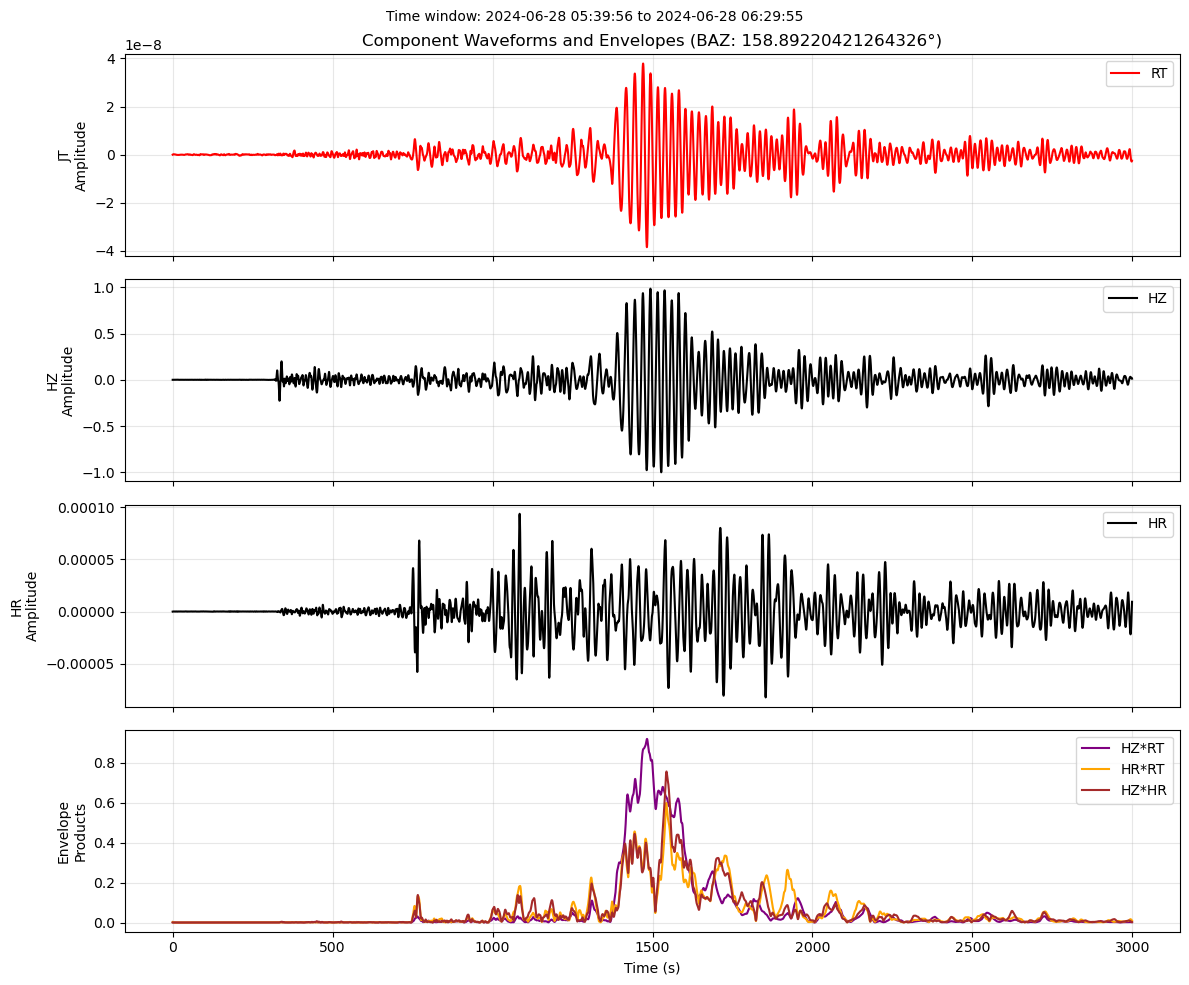

In [38]:
fig = plot_waveforms_and_envelope_products(
    stream_rot=sd.get_stream("rotation"),
    stream_tra=sd.get_stream("translation"),
    smooth_window=100,
    baz_theo=ev['backazimuth']
)

In [39]:

import pandas as pd
from tqdm.notebook import tqdm
from obspy.signal.cross_correlation import correlate, xcorr_max

tbeg = HZ[0].stats.starttime
tend = HZ[0].stats.endtime

#  precompute time windows for the moving windows based on indicies with overlap of 50%
times = sd.get_time_intervals(tbeg=tbeg,
                              tend=tend,
                              interval_seconds=50,
                              interval_overlap=40
                              )

RN = sd.get_stream("rotation").select(channel="*N").copy()
RE = sd.get_stream("rotation").select(channel="*E").copy()

HZ = sd.get_stream("translation").select(channel="*Z").copy()
HN = sd.get_stream("translation").select(channel="*N").copy()
HE = sd.get_stream("translation").select(channel="*E").copy()

df = pd.DataFrame(columns=["tt", "t1", "t2", "lag1", "lag2", "cc1", "cc2", "cc0"])
for t1, t2 in tqdm(times):

    tt = (t2 - t1) + (t1 - tbeg)

    rn = RN.copy().trim(starttime=t1, endtime=t2)[0].data
    re = RE.copy().trim(starttime=t1, endtime=t2)[0].data
    hz = HZ.copy().trim(starttime=t1, endtime=t2)[0].data
    hn = HN.copy().trim(starttime=t1, endtime=t2)[0].data
    he = HE.copy().trim(starttime=t1, endtime=t2)[0].data

    rr, rt = rotate_ne_rt(rn, re, ev['backazimuth'])
    hr, ht = rotate_ne_rt(hn, he, ev['backazimuth'])

    N = len(hz)

    # compute the cross-correlation between hz and rt
    cc0 = correlate(hz, rt, shift=0, method='fft')

    # compute the cross-correlation between hz and rt
    ccf1 = correlate(hz, rt, shift=N, method='fft')
    lag1, cc1 = xcorr_max(ccf1)

    # compute the cross-correlation between hz and rt
    cc2 = correlate(hr, hz-rt, shift=0, method='fft')


    # Create a new single-row DataFrame
    new_row = pd.DataFrame({"tt": tt, "t1": t1, "t2": t2, "lag1": lag1, "lag2": lag2, "cc1": cc1, "cc2": cc2, "cc0": cc0}, index=[0])

    # Concatenate with the existing DataFrame
    df = pd.concat([df, new_row], ignore_index=True)

    

AttributeError: 'numpy.float64' object has no attribute 'stats'

In [54]:
def analyze_component_correlations(stream_rot, stream_tra, wave_type='rayleigh', 
                                  window_sec=30, overlap=0.5, baz_theo=None, 
                                  hr_phase_shift=0, cc_threshold=0.0, 
                                  plot=True, figsize=(15, 10)):
    """
    Analyze correlations between different component combinations in overlapping time windows.
    
    Parameters:
    -----------
    stream_rot : obspy.Stream
        Stream containing rotation components
    stream_tra : obspy.Stream
        Stream containing translation components
    wave_type : str
        Type of wave to analyze ('rayleigh' or 'love')
    window_sec : float
        Window length in seconds
    overlap : float
        Window overlap (0-1)
    baz_theo : float, optional
        Theoretical backazimuth in degrees
    hr_phase_shift : int
        Number of samples to shift HR component (positive = delay HR)
    cc_threshold : float
        Minimum correlation coefficient to include in results (0-1)
    plot : bool
        Whether to plot the results
    figsize : tuple
        Figure size for plots
        
    Returns:
    --------
    pandas.DataFrame
        DataFrame with correlation analysis results
    matplotlib.figure.Figure, optional
        Figure if plot=True
    """
    import pandas as pd
    import numpy as np
    from obspy.signal.cross_correlation import correlate, xcorr_max
    from obspy.signal.rotate import rotate_ne_rt
    import matplotlib.pyplot as plt
    from matplotlib.gridspec import GridSpec
    
    # Make copies of streams to avoid modifying originals
    rot_stream = stream_rot.copy()
    tra_stream = stream_tra.copy()
    
    # Use provided backazimuth or default
    if baz_theo is None:
        baz_theo = 0
        print(f"Warning: No backazimuth provided, using {baz_theo}°")
    
    # Get start and end times
    tbeg = max([tr.stats.starttime for tr in rot_stream + tra_stream])
    tend = min([tr.stats.endtime for tr in rot_stream + tra_stream])
    sampling_rate = tra_stream[0].stats.sampling_rate
    
    # Precompute time windows with overlap
    window_samples = int(window_sec * sampling_rate)
    step_samples = int(window_samples * (1 - overlap))
    
    # Create time windows
    times = []
    current_time = tbeg
    while current_time + window_sec <= tend:
        times.append((current_time, current_time + window_sec))
        current_time += window_sec * (1 - overlap)
    
    # Get components
    try:
        # Rotation components
        RN = rot_stream.select(channel="*N")[0].copy()
        RE = rot_stream.select(channel="*E")[0].copy()
        
        # Translation components
        HZ = tra_stream.select(channel="*Z")[0].copy()
        HN = tra_stream.select(channel="*N")[0].copy()
        HE = tra_stream.select(channel="*E")[0].copy()
    except IndexError:
        raise ValueError("Required components not found in streams")
    
    # Create empty list to collect results
    results = []
    
    # Process each time window
    for t1, t2 in times:
        # Calculate window center time relative to start
        window_center = t1 + (t2 - t1) / 2
        tt = (window_center - tbeg)
        
        # Get data for this window
        rn = np.array(RN.copy().trim(starttime=t1, endtime=t2)[0].data)
        re = np.array(RE.copy().trim(starttime=t1, endtime=t2)[0].data)
        hz = np.array(HZ.copy().trim(starttime=t1, endtime=t2)[0].data)
        hn = np.array(HN.copy().trim(starttime=t1, endtime=t2)[0].data)
        he = np.array(HE.copy().trim(starttime=t1, endtime=t2)[0].data)
        
        # Rotate to radial-transverse
        rr, rt = rotate_ne_rt(rn, re, baz_theo)
        hr, ht = rotate_ne_rt(hn, he, baz_theo)
        
        # Apply phase shift to HR if specified
        if hr_phase_shift != 0:
            hr_shifted = np.roll(hr, hr_phase_shift)
            if hr_phase_shift > 0:
                hr_shifted[:hr_phase_shift] = 0
            else:
                hr_shifted[hr_phase_shift:] = 0
            hr = hr_shifted
        
        # Create combined signals
        hz_plus_hr = hz + hr
        hz_minus_hr = hz - hr
        
        # Normalize signals for correlation
        def normalize(x):
            return (x - np.mean(x)) / np.std(x)
        
        rt_norm = normalize(rt)
        hz_norm = normalize(hz)
        hr_norm = normalize(hr)
        hz_plus_hr_norm = normalize(hz_plus_hr)
        hz_minus_hr_norm = normalize(hz_minus_hr)
        
        # Window length
        N = len(hz)
        
        # 1. Zero-lag CC of HZ and RT
        cc_hz_rt_zero = np.corrcoef(hz_norm, rt_norm)[0, 1]
        
        # 2. Max CC and lag of HZ and RT
        ccf_hz_rt = correlate(hz_norm, rt_norm, shift=N, method='fft')
        lag_hz_rt, cc_hz_rt_max = xcorr_max(ccf_hz_rt, abs_max=False)
        
        # 3. Zero-lag CC of HR and RT
        cc_hr_rt_zero = np.corrcoef(hr_norm, rt_norm)[0, 1]
        
        # 4. Max CC and lag of HR and RT
        ccf_hr_rt = correlate(hr_norm, rt_norm, shift=N, method='fft')
        lag_hr_rt, cc_hr_rt_max = xcorr_max(ccf_hr_rt, abs_max=False)
        
        # 5. Zero-lag CC of HZ+HR and RT
        cc_hz_plus_hr_rt_zero = np.corrcoef(hz_plus_hr_norm, rt_norm)[0, 1]
        
        # 6. Max CC and lag of HZ+HR and RT
        ccf_hz_plus_hr_rt = correlate(hz_plus_hr_norm, rt_norm, shift=N, method='fft')
        lag_hz_plus_hr_rt, cc_hz_plus_hr_rt_max = xcorr_max(ccf_hz_plus_hr_rt, abs_max=False)
        
        # 7. Zero-lag CC of HZ-HR and RT
        cc_hz_minus_hr_rt_zero = np.corrcoef(hz_minus_hr_norm, rt_norm)[0, 1]
        
        # 8. Max CC and lag of HZ-HR and RT
        ccf_hz_minus_hr_rt = correlate(hz_minus_hr_norm, rt_norm, shift=N, method='fft')
        lag_hz_minus_hr_rt, cc_hz_minus_hr_rt_max = xcorr_max(ccf_hz_minus_hr_rt, abs_max=False)
        
        # Convert lags to seconds
        lag_hz_rt_sec = lag_hz_rt / sampling_rate
        lag_hr_rt_sec = lag_hr_rt / sampling_rate
        lag_hz_plus_hr_rt_sec = lag_hz_plus_hr_rt / sampling_rate
        lag_hz_minus_hr_rt_sec = lag_hz_minus_hr_rt / sampling_rate
        
        # Store results
        results.append({
            'time': tt,
            't1': t1,
            't2': t2,
            # HZ and RT
            'cc_hz_rt_zero': cc_hz_rt_zero,
            'cc_hz_rt_max': cc_hz_rt_max,
            'lag_hz_rt': lag_hz_rt,
            'lag_hz_rt_sec': lag_hz_rt_sec,
            # HR and RT
            'cc_hr_rt_zero': cc_hr_rt_zero,
            'cc_hr_rt_max': cc_hr_rt_max,
            'lag_hr_rt': lag_hr_rt,
            'lag_hr_rt_sec': lag_hr_rt_sec,
            # HZ+HR and RT
            'cc_hz_plus_hr_rt_zero': cc_hz_plus_hr_rt_zero,
            'cc_hz_plus_hr_rt_max': cc_hz_plus_hr_rt_max,
            'lag_hz_plus_hr_rt': lag_hz_plus_hr_rt,
            'lag_hz_plus_hr_rt_sec': lag_hz_plus_hr_rt_sec,
            # HZ-HR and RT
            'cc_hz_minus_hr_rt_zero': cc_hz_minus_hr_rt_zero,
            'cc_hz_minus_hr_rt_max': cc_hz_minus_hr_rt_max,
            'lag_hz_minus_hr_rt': lag_hz_minus_hr_rt,
            'lag_hz_minus_hr_rt_sec': lag_hz_minus_hr_rt_sec
        })
    
    # Create DataFrame
    df = pd.DataFrame(results)
    
    # Apply correlation threshold if specified
    if cc_threshold > 0:
        # Create mask for each correlation type
        mask_hz = df['cc_hz_rt_max'] >= cc_threshold
        mask_hr = df['cc_hr_rt_max'] >= cc_threshold
        mask_plus = df['cc_hz_plus_hr_rt_max'] >= cc_threshold
        mask_minus = df['cc_hz_minus_hr_rt_max'] >= cc_threshold
        
        # Apply masks to respective columns
        df_filtered = df.copy()
        
        # Apply masks to respective columns (only for visualization)
        df_filtered.loc[~mask_hz, ['cc_hz_rt_zero', 'cc_hz_rt_max', 'lag_hz_rt', 'lag_hz_rt_sec']] = np.nan
        df_filtered.loc[~mask_hr, ['cc_hr_rt_zero', 'cc_hr_rt_max', 'lag_hr_rt', 'lag_hr_rt_sec']] = np.nan
        df_filtered.loc[~mask_plus, ['cc_hz_plus_hr_rt_zero', 'cc_hz_plus_hr_rt_max', 'lag_hz_plus_hr_rt', 'lag_hz_plus_hr_rt_sec']] = np.nan
        df_filtered.loc[~mask_minus, ['cc_hz_minus_hr_rt_zero', 'cc_hz_minus_hr_rt_max', 'lag_hz_minus_hr_rt', 'lag_hz_minus_hr_rt_sec']] = np.nan
    else:
        df_filtered = df
    
    # Plot results if requested
    if plot:
        fig = plt.figure(figsize=figsize)
        gs = GridSpec(4, 2, figure=fig, height_ratios=[1, 1, 1, 1], width_ratios=[3, 1])
        
        # Create subplots
        ax_cc_zero = fig.add_subplot(gs[0, 0])
        ax_cc_max = fig.add_subplot(gs[1, 0], sharex=ax_cc_zero)
        ax_lag = fig.add_subplot(gs[2, 0], sharex=ax_cc_zero)
        ax_lag_hist = fig.add_subplot(gs[2, 1])
        ax_cc_hist = fig.add_subplot(gs[3, :])
        
        # Plot zero-lag correlations
        ax_cc_zero.plot(df_filtered['time'], df_filtered['cc_hz_rt_zero'], 'b-', label='HZ & RT', alpha=0.7)
        ax_cc_zero.plot(df_filtered['time'], df_filtered['cc_hr_rt_zero'], 'g-', label='HR & RT', alpha=0.7)
        ax_cc_zero.plot(df_filtered['time'], df_filtered['cc_hz_plus_hr_rt_zero'], 'r-', label='HZ+HR & RT', alpha=0.7)
        ax_cc_zero.plot(df_filtered['time'], df_filtered['cc_hz_minus_hr_rt_zero'], 'm-', label='HZ-HR & RT', alpha=0.7)
        ax_cc_zero.set_ylabel('Zero-lag CC')
        ax_cc_zero.set_title('Zero-lag Cross-Correlation')
        ax_cc_zero.grid(True, alpha=0.3)
        ax_cc_zero.legend(loc='upper right')
        
        # Plot max correlations
        ax_cc_max.plot(df_filtered['time'], df_filtered['cc_hz_rt_max'], 'b-', label='HZ & RT', alpha=0.7)
        ax_cc_max.plot(df_filtered['time'], df_filtered['cc_hr_rt_max'], 'g-', label='HR & RT', alpha=0.7)
        ax_cc_max.plot(df_filtered['time'], df_filtered['cc_hz_plus_hr_rt_max'], 'r-', label='HZ+HR & RT', alpha=0.7)
        ax_cc_max.plot(df_filtered['time'], df_filtered['cc_hz_minus_hr_rt_max'], 'm-', label='HZ-HR & RT', alpha=0.7)
        ax_cc_max.set_ylabel('Max CC')
        ax_cc_max.set_title('Maximum Cross-Correlation')
        ax_cc_max.grid(True, alpha=0.3)
        ax_cc_max.legend(loc='upper right')
        
        # Plot time lags
        ax_lag.plot(df_filtered['time'], df_filtered['lag_hz_rt_sec'], 'b-', label='HZ & RT', alpha=0.7)
        ax_lag.plot(df_filtered['time'], df_filtered['lag_hr_rt_sec'], 'g-', label='HR & RT', alpha=0.7)
        ax_lag.plot(df_filtered['time'], df_filtered['lag_hz_plus_hr_rt_sec'], 'r-', label='HZ+HR & RT', alpha=0.7)
        ax_lag.plot(df_filtered['time'], df_filtered['lag_hz_minus_hr_rt_sec'], 'm-', label='HZ-HR & RT', alpha=0.7)
        ax_lag.set_ylabel('Time Lag (s)')
        ax_lag.set_xlabel('Time (s)')
        ax_lag.set_title('Time Lag at Maximum Correlation')
        ax_lag.grid(True, alpha=0.3)
        ax_lag.legend(loc='upper right')
        
        # Plot lag histograms
        bins = np.linspace(-2, 2, 41)  # Adjust bin range as needed
        ax_lag_hist.hist(df_filtered['lag_hz_rt_sec'].dropna(), bins=bins, alpha=0.3, color='b', label='HZ & RT')
        ax_lag_hist.hist(df_filtered['lag_hr_rt_sec'].dropna(), bins=bins, alpha=0.3, color='g', label='HR & RT')
        ax_lag_hist.hist(df_filtered['lag_hz_plus_hr_rt_sec'].dropna(), bins=bins, alpha=0.3, color='r', label='HZ+HR & RT')
        ax_lag_hist.hist(df_filtered['lag_hz_minus_hr_rt_sec'].dropna(), bins=bins, alpha=0.3, color='m', label='HZ-HR & RT')
        ax_lag_hist.set_xlabel('Time Lag (s)')
        ax_lag_hist.set_ylabel('Count')
        ax_lag_hist.grid(True, alpha=0.3)
        
        # Plot correlation coefficient distributions
        bins = np.linspace(-1, 1, 41)
        ax_cc_hist.hist(df_filtered['cc_hz_rt_max'].dropna(), bins=bins, alpha=0.3, color='b', label='HZ & RT')
        ax_cc_hist.hist(df_filtered['cc_hr_rt_max'].dropna(), bins=bins, alpha=0.3, color='g', label='HR & RT')
        ax_cc_hist.hist(df_filtered['cc_hz_plus_hr_rt_max'].dropna(), bins=bins, alpha=0.3, color='r', label='HZ+HR & RT')
        ax_cc_hist.hist(df_filtered['cc_hz_minus_hr_rt_max'].dropna(), bins=bins, alpha=0.3, color='m', label='HZ-HR & RT')
        ax_cc_hist.set_xlabel('Correlation Coefficient')
        ax_cc_hist.set_ylabel('Count')
        ax_cc_hist.set_title('Distribution of Maximum Correlation Coefficients')
        ax_cc_hist.grid(True, alpha=0.3)
        ax_cc_hist.legend(loc='upper left')
        
        # Add summary statistics as text
        stats_text = (
            f"Mean Max CC:\n"
            f"  HZ & RT: {df_filtered['cc_hz_rt_max'].mean():.3f}\n"
            f"  HR & RT: {df_filtered['cc_hr_rt_max'].mean():.3f}\n"
            f"  HZ+HR & RT: {df_filtered['cc_hz_plus_hr_rt_max'].mean():.3f}\n"
            f"  HZ-HR & RT: {df_filtered['cc_hz_minus_hr_rt_max'].mean():.3f}\n\n"
            f"Mean Lag (s):\n"
            f"  HZ & RT: {df_filtered['lag_hz_rt_sec'].mean():.3f}\n"
            f"  HR & RT: {df_filtered['lag_hr_rt_sec'].mean():.3f}\n"
            f"  HZ+HR & RT: {df_filtered['lag_hz_plus_hr_rt_sec'].mean():.3f}\n"
            f"  HZ-HR & RT: {df_filtered['lag_hz_minus_hr_rt_sec'].mean():.3f}"
        )
        
        plt.figtext(0.02, 0.02, stats_text, fontsize=10,
                   bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
        
        plt.tight_layout()
        plt.subplots_adjust(hspace=0.3)
        
        return df, fig
    
    return df

In [ ]:
df, fig = analyze_component_correlations(
    stream_rot=sd.get_stream("rotation"),  # ObsPy Stream with rotation components
    stream_tra=sd.get_stream("translation"),  # ObsPy Stream with translation components
    wave_type='rayleigh',
    window_sec=30,
    overlap=0.5,
    baz_theo=256.4,  # Backazimuth in degrees
    plot=True
)

In [56]:
def plot_waveform_combinations(self, time_window=None, invert_acc_z=False,
                              normalize=True, figsize=(12, 10)):
    """
    Plot comparison of waveform combinations to analyze relationships between
    rotational and translational components.
    
    Parameters:
    -----------
    time_window : tuple, optional
        (start_time, end_time) in seconds relative to trace start
    filter_params : dict, optional
        Dictionary with filter parameters:
        {
            'type': 'bandpass',
            'freqmin': 0.01,
            'freqmax': 0.1,
            'corners': 4,
            'zerophase': True
        }
    normalize : bool
        Whether to normalize waveforms for better comparison
    figsize : tuple
        Figure size (width, height) in inches
        
    Returns:
    --------
    fig : matplotlib.figure.Figure
        The created figure
    correlations : dict
        Dictionary with correlation coefficients between combinations
    """
    import numpy as np
    import matplotlib.pyplot as plt
    from obspy.signal.rotate import rotate_ne_rt
    
    # Get streams
    rot_stream = self.get_stream("rotation").copy()
    tra_stream = self.get_stream("translation").copy()
    
    # Check if streams exist
    if rot_stream is None or tra_stream is None:
        raise ValueError("Rotation or translation streams not available")
    
    # Get components
    try:
        # Rotation components
        rot_n = rot_stream.select(channel="*N")[0].copy()
        rot_e = rot_stream.select(channel="*E")[0].copy()
        
        # Translation components
        tra_n = tra_stream.select(channel="*N")[0].copy()
        tra_e = tra_stream.select(channel="*E")[0].copy()
        tra_z = tra_stream.select(channel="*Z")[0].copy()
    except IndexError:
        raise ValueError("Required components not found in streams")
    
    # Get sampling rate and time array
    sampling_rate = tra_z.stats.sampling_rate
    time = np.arange(0, len(tra_z.data)) / sampling_rate
    
    # Apply time window if specified
    if time_window is not None:
        start_idx = int(time_window[0] * sampling_rate)
        end_idx = int(time_window[1] * sampling_rate)
        
        # Ensure indices are within bounds
        start_idx = max(0, start_idx)
        end_idx = min(len(time), end_idx)
        
        time = time[start_idx:end_idx]
        
        # Trim data
        for tr in [rot_n, rot_e, tra_n, tra_e, tra_z]:
            tr.data = tr.data[start_idx:end_idx]
    
    # Rotate components to radial-transverse
    if self.baz_theo is not None:
        baz = self.baz_theo
    else:
        # Use default backazimuth if not specified
        baz = 0
        print("Warning: No theoretical backazimuth specified, using 0°")
    
    # Rotate components
    rot_r, rot_t = rotate_ne_rt(rot_n.data, rot_e.data, baz)
    tra_r, tra_t = rotate_ne_rt(tra_n.data, tra_e.data, baz)
    
    # Create combinations
    if invert_acc_z:
        hz = tra_z.data *-1
    else:
        hz = tra_z.data
    hr = tra_r
    rt = rot_t
    hz_plus_hr = hz + hr
    hz_minus_hr = hz - hr
    
    # Normalize if requested
    if normalize:
        def norm(x):
            return x / np.max(np.abs(x))
        
        rt = norm(rt)
        hz = norm(hz)
        hr = norm(hr)
        hz_plus_hr = norm(hz_plus_hr)
        hz_minus_hr = norm(hz_minus_hr)
    
    # Calculate correlations
    correlations = {
        'RT_HZ': np.corrcoef(rt, hz)[0, 1],
        'RT_HR': np.corrcoef(rt, hr)[0, 1],
        'RT_HZ+HR': np.corrcoef(rt, hz_plus_hr)[0, 1],
        'RT_HZ-HR': np.corrcoef(rt, hz_minus_hr)[0, 1]
    }
    
    # Create figure
    fig, axes = plt.subplots(4, 1, figsize=figsize, sharex=True)
    
    # Plot combinations
    axes[0].plot(time, rt, 'k-', label='RT', linewidth=1)
    axes[0].plot(time, hz, 'r-', label='HZ', linewidth=1)
    axes[0].set_title(f'RT vs HZ (CC: {correlations["RT_HZ"]:.3f})')
    axes[0].legend(loc='upper right')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(time, rt, 'k-', label='RT', linewidth=1)
    axes[1].plot(time, hr, 'b-', label='HR', linewidth=1)
    axes[1].set_title(f'RT vs HR (CC: {correlations["RT_HR"]:.3f})')
    axes[1].legend(loc='upper right')
    axes[1].grid(True, alpha=0.3)
    
    axes[2].plot(time, rt, 'k-', label='RT', linewidth=1)
    axes[2].plot(time, hz_plus_hr, 'g-', label='HZ+HR', linewidth=1)
    axes[2].set_title(f'RT vs HZ+HR (CC: {correlations["RT_HZ+HR"]:.3f})')
    axes[2].legend(loc='upper right')
    axes[2].grid(True, alpha=0.3)
    
    axes[3].plot(time, rt, 'k-', label='RT', linewidth=1)
    axes[3].plot(time, hz_minus_hr, 'm-', label='HZ-HR', linewidth=1)
    axes[3].set_title(f'RT vs HZ-HR (CC: {correlations["RT_HZ-HR"]:.3f})')
    axes[3].legend(loc='upper right')
    axes[3].grid(True, alpha=0.3)
    
    # Add y-labels
    for ax in axes:
        if normalize:
            ax.set_ylabel('Normalized Amplitude')
        else:
            ax.set_ylabel('Amplitude')
    
    # Add x-label to bottom subplot
    axes[-1].set_xlabel('Time (s)')
    
    # Add text box with correlation summary
    # textstr = '\n'.join([
    #     f'Correlation Coefficients:',
    #     f'RT vs HZ: {correlations["RT_HZ"]:.3f}',
    #     f'RT vs HR: {correlations["RT_HR"]:.3f}',
    #     f'RT vs HZ+HR: {correlations["RT_HZ+HR"]:.3f}',
    #     f'RT vs HZ-HR: {correlations["RT_HZ-HR"]:.3f}'
    # ])
    
    # Add text box to figure
    # plt.figtext(0.02, 0.02, textstr, fontsize=10,
    #            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.9, bottom=0.1)
    
    return fig, correlations

In [ ]:
# Basic usage
fig, corr = plot_waveform_combinations(sd, invert_acc_z=True, normalize=True)


# Print correlation coefficients
print(corr)

In [58]:
# fig, results = sd.compare_backazimuth_methods(
#     Twin=20.0,
#     Toverlap=0.5,
#     invert_rot_z=False,
#     invert_acc_z=False,
#     cc_threshold=0.1,
#     baz_theo=ev['backazimuth'],
#     plot=True,
#     output=True
# )

### Analyse phase velocities

### Compare RANSAC and ODR

In [112]:

# Compute Rayleigh wave velocities
rayleigh_velocities_ransac = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=T,
    overlap=0.5,
    cc_threshold=0.5,
    method='ransac',
    baz=ev['backazimuth']  # optional
)


# Compute Rayleigh wave velocities
rayleigh_velocities_odr = sd.compute_velocities(
    wave_type='rayleigh',
    win_time_s=T,
    overlap=0.5,
    cc_threshold=0.7,
    method='odr',
    baz=ev['backazimuth']  # optional
)

/home/andbro/cursorfiles/BRS/sixdegrees.py:5582: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  lon_error = abs(lons_deg[0] - lon0)


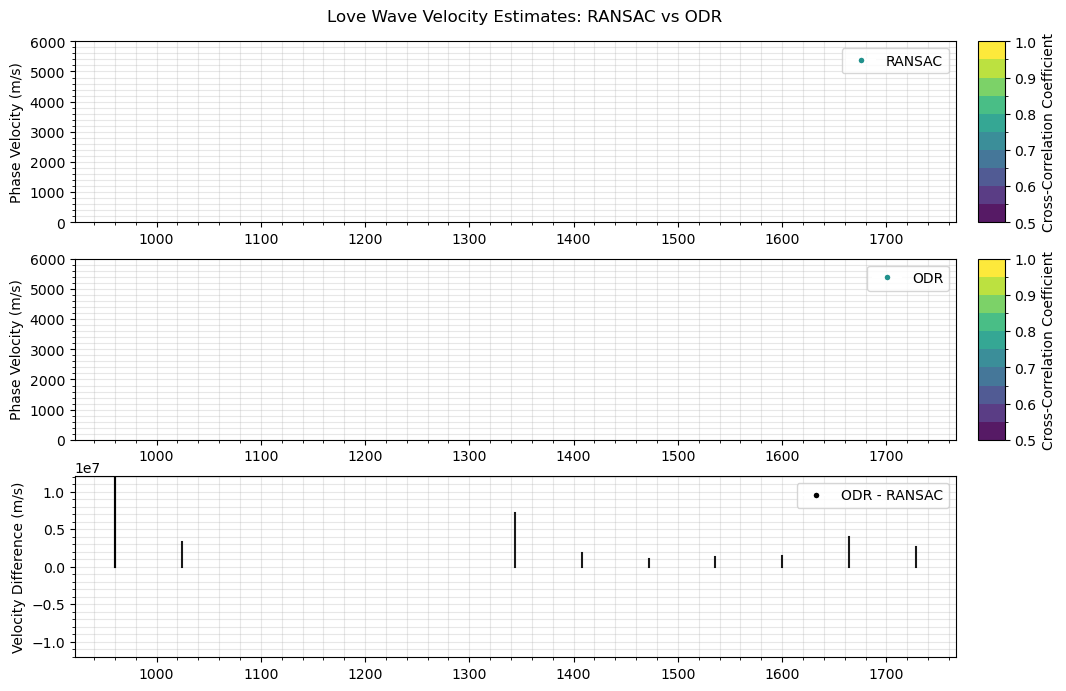

In [113]:
fig = sd.plot_velocity_method_comparison(rayleigh_velocities_ransac,
                                         rayleigh_velocities_odr)